# First end-to-end rain map, checked against MRMS: KTLX, 5 May 2022

**radar-wow verification.** Four hours of a widespread rain event over central Oklahoma, every volume
from the NEXRAD KTLX radar (S band), run through the whole radar-wow chain:

`open_volume` -> melting layer from QVPs (Sanchez-Rivas & Rico-Ramirez 2021) -> `Vulpiani2012KDP`
-> `Testud2000ZPHI` -> `SyntheticRainRate` -> hourly `accumulate`

**Reference.** MRMS MultiSensor QPE Pass 2: radar QPE adjusted with rain gauges (Zhang et al. 2016,
BAMS, doi:10.1175/BAMS-D-14-00174.1). It is independent of our processing but not truth: it shares
radar input and has its own errors. MRMS radar-only QPE is shown as a peer benchmark.

**Data note.** KTLX has no archived volumes from 02 to 05 UTC that night, during the heaviest rain:
real radars have outages, which is one reason national systems build mosaics from several radars.
We use 07-11 UTC, the four hours with complete coverage.

In [1]:
# Colab: uncomment to install (downloads ~700 MB of radar data on first run)
!pip install -q cfgrib eccodes "git+https://github.com/radar-wow/radarwow-core" "git+https://github.com/radar-wow/radarwow-kdp" "git+https://github.com/radar-wow/radarwow-attenuation" "git+https://github.com/radar-wow/radarwow-estimation" "git+https://github.com/radar-wow/radarwow-classification" "git+https://github.com/radar-wow/radarwow-verify"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Markdown, display

from radarwow.attenuation import Testud2000ZPHI
from radarwow.classification import MeltingLayerTracker, melting_layer_from_volume
from radarwow.core import nexrad_aws_files, open_volume
from radarwow.estimation import SyntheticRainRate, ZRRelation, accumulate, to_fixed_azimuths
from radarwow.kdp import Vulpiani2012KDP
from radarwow.verify import fetch_mrms, gate_latlon, hrrr_freezing_level, scores, to_mrms_grid

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITE, START, END = "KTLX", "2022-05-05 06:00", "2022-05-05 11:00"
HOURS = [7, 8, 9, 10]
NG = 600  # gates to 150 km

## 1. Run the chain on every volume

In [3]:
files = nexrad_aws_files(SITE, START, END, cache_dir=f"{CACHE}/nexrad")
print(len(files), "volumes from", files[0][0], "to", files[-1][0])

tracker = MeltingLayerTracker()
ml_log, scans, meta = [], {"synthetic": [], "synthetic, no ML mask": [], "Z-R Marshall-Palmer": [], "Z-R WSR-88D": []}, {}
for t, f in files:
    dt = open_volume(f, band="S")
    ml, _ = melting_layer_from_volume(dt)
    use, status = tracker.update(t, ml)
    ml_log.append(dict(time=t, detected=ml.detected, elev=ml.elevation_deg, bottom=ml.bottom_km, top=ml.top_km, status=status,
                       used_bottom=use.bottom_km if use else np.nan, used_top=use.top_km if use else np.nan))
    low = min((float(np.nanmedian(n.to_dataset()["elevation"].values)), name) for name, n in dt.children.items()
              if name.startswith("sweep") and "DBZH" in n.to_dataset() and "PHIDP" in n.to_dataset())[1]
    ds = dt[low].to_dataset().isel(range=slice(0, NG))
    att = Testud2000ZPHI()(Vulpiani2012KDP()(ds, band="S"), band="S")
    mlb = use.bottom_km if use else None
    rates = {"synthetic": SyntheticRainRate(temperature_c=20, ml_bottom_km=mlb)(att, band="S")["RATE"],
             "synthetic, no ML mask": SyntheticRainRate(temperature_c=20)(att, band="S")["RATE"],
             "Z-R Marshall-Palmer": ZRRelation(preset="marshall_palmer", z_max_dbz=53, ml_bottom_km=mlb)(ds, band="S")["RATE_Z"],
             "Z-R WSR-88D": ZRRelation(preset="nexrad_convective", ml_bottom_km=mlb)(ds, band="S")["RATE_Z"]}
    for k, v in rates.items():
        scans[k].append((t, to_fixed_azimuths(v)))
    meta = dict(range=ds["range"].values, elevation=float(np.nanmedian(ds["elevation"].values)),
                lat=float(dt["latitude"].values), lon=float(dt["longitude"].values), alt=float(dt["altitude"].values))
ml_log = pd.DataFrame(ml_log)
display(Markdown(f"Melting layer detected in {ml_log.detected.sum()} of {len(ml_log)} volumes; "
                 f"{(ml_log.status == 'rejected (jump)').sum()} detections rejected as implausible jumps."))

44 volumes from 2022-05-05 06:11:42 to 2022-05-05 10:57:53


Melting layer detected in 23 of 44 volumes; 5 detections rejected as implausible jumps.

## 2. Melting layer: radar QVPs against the HRRR model
Rain relations hold only below the melting layer. We detect it from QVPs of the highest sweeps (12-19.5 deg)
and compare with the 0 C height of the HRRR analysis (median within 150 km). The melting layer top should sit
at or a few hundred metres below the 0 C level.

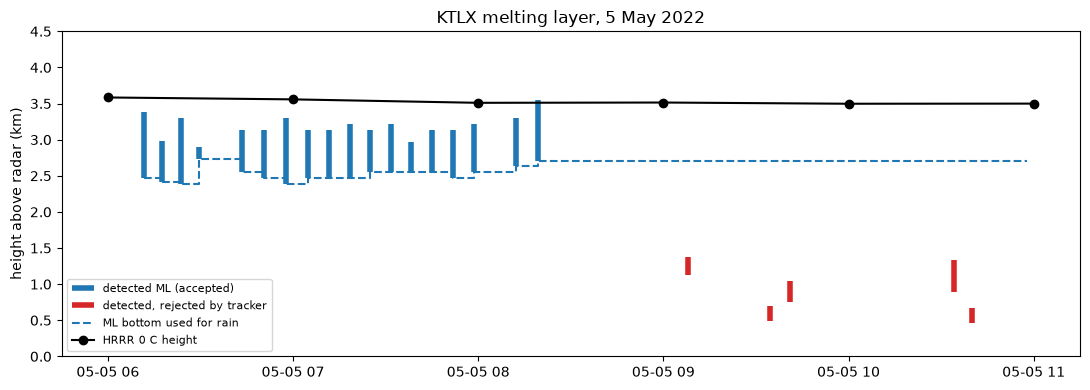

In [4]:
hrrr = pd.DataFrame([dict(time=pd.Timestamp(f"2022-05-05 {h:02d}:00"),
                          fz=(hrrr_freezing_level(f"2022-05-05 {h:02d}:00", meta["lat"], meta["lon"], f"{CACHE}/hrrr", 150) - meta["alt"]) / 1e3)
                     for h in range(6, 12)])
fig, ax = plt.subplots(figsize=(11, 4))
d = ml_log[ml_log.detected]
acc_ = d.status == "accepted"
ax.vlines(d.time[acc_], d.bottom[acc_], d.top[acc_], color="C0", lw=4, label="detected ML (accepted)")
ax.vlines(d.time[~acc_], d.bottom[~acc_], d.top[~acc_], color="C3", lw=4, label="detected, rejected by tracker")
ax.step(ml_log.time, ml_log.used_bottom, where="post", color="C0", ls="--", label="ML bottom used for rain")
ax.plot(hrrr.time, hrrr.fz, "ko-", label="HRRR 0 C height")
ax.set(ylabel="height above radar (km)", ylim=(0, 4.5), title="KTLX melting layer, 5 May 2022")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG}/01_melting_layer.png", dpi=110)
plt.show()

Before 08:20 the layer is found on 18 volumes, with its top 0-0.6 km below the model 0 C level, as expected.
After 09 UTC the rain over the radar thins and the "detections" are 0.5-1.4 km high: low non-meteorological
echo (the paper removed such echo before building profiles; we do not yet). The tracker rejects them as jumps
and keeps the last good layer.

## 3. Hourly totals against MRMS

In [5]:
az = (np.arange(720) + 0.5) * 0.5
lat, lon, ground = gate_latlon(meta["range"], az, meta["elevation"], meta["lat"], meta["lon"])
gk = ground / 1e3
results, maps = [], {}
for h in HOURS:
    a, b = pd.Timestamp(f"2022-05-05 {h:02d}:00"), pd.Timestamp(f"2022-05-05 {h + 1:02d}:00")
    ref = fetch_mrms("gauge_corrected", b, f"{CACHE}/mrms")
    ro = fetch_mrms("radar_only", b, f"{CACHE}/mrms")
    for k, sc in scans.items():
        acc = accumulate(sc, a, b)
        val = np.where(acc["VALID_MINUTES"].values >= 48, acc["ACCUM"].values, np.nan)  # >= 80 % of the hour
        maps[(h, k)] = val
        ours, theirs, dist = to_mrms_grid(val, lat, lon, ref, gk)
        for lo_, hi_ in [(0, 150), (0, 50), (50, 100), (100, 150)]:
            m = (dist >= lo_) & (dist < hi_)
            results.append(dict(hour=f"{h:02d}-{h + 1:02d}", method=k, ring=f"{lo_}-{hi_} km", **scores(ours[m], theirs[m])))
    ones = np.where(np.isfinite(maps[(h, "synthetic")]), 1.0, np.nan)
    _, ro_v, dist = to_mrms_grid(ones, lat, lon, ro, gk)
    _, gc_v, _ = to_mrms_grid(ones, lat, lon, ref, gk)
    results.append(dict(hour=f"{h:02d}-{h + 1:02d}", method="MRMS radar-only", ring="0-150 km", **scores(ro_v, gc_v)))
    maps[(h, "mrms")], maps[(h, "mrms_ro")] = ref, ro
res = pd.DataFrame(results)

tab = res[res.ring == "0-150 km"].pivot_table(index="method", columns="hour", values=["bias_ratio", "corr"]).round(2)
display(Markdown("**All cells within 150 km** (bias = our total / MRMS total; corr = correlation of hourly cell totals)\n\n" + tab.to_markdown()))

**All cells within 150 km** (bias = our total / MRMS total; corr = correlation of hourly cell totals)

| method                |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |
|:----------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| MRMS radar-only       |                      1.1  |                      1.14 |                      1.26 |                      1.22 |                0.98 |                0.99 |                0.98 |                0.97 |
| Z-R Marshall-Palmer   |                      1.11 |                      0.98 |                      1.11 |                      1.03 |                0.93 |                0.89 |                0.9  |                0.84 |
| Z-R WSR-88D           |                      1.16 |                      1    |                      1.12 |                      1.07 |                0.93 |                0.89 |                0.91 |                0.84 |
| synthetic             |                      1.18 |                      1.06 |                      1.18 |                      1.08 |                0.94 |                0.93 |                0.92 |                0.77 |
| synthetic, no ML mask |                      1.19 |                      1.08 |                      1.19 |                      1.08 |                0.94 |                0.93 |                0.92 |                0.77 |

In [6]:
syn = res[(res.method == "synthetic") & (res.ring != "0-150 km")].pivot_table(index="ring", columns="hour", values=["bias_ratio", "corr"]).round(2)
display(Markdown("**Synthetic estimator by distance from the radar**\n\n" + syn.to_markdown()))

**Synthetic estimator by distance from the radar**

| ring       |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |
|:-----------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| 0-50 km    |                      1.29 |                      1.02 |                      0.96 |                      1.01 |                0.9  |                0.89 |                0.96 |                0.85 |
| 100-150 km |                      1.22 |                      1.17 |                      1.53 |                      1.22 |                0.93 |                0.86 |                0.81 |                0.63 |
| 50-100 km  |                      1.11 |                      1.03 |                      1.1  |                      1.02 |                0.94 |                0.94 |                0.95 |                0.8  |

## 4. Maps for one hour

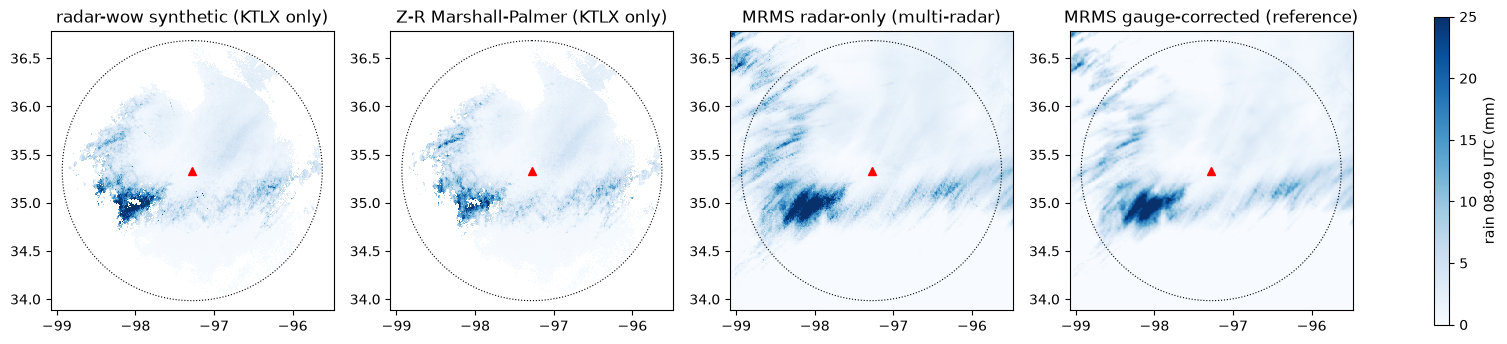

In [7]:
h = 8
ref = maps[(h, "mrms")]
box = ref.sel(latitude=slice(meta["lat"] + 1.45, meta["lat"] - 1.45), longitude=slice(meta["lon"] - 1.8, meta["lon"] + 1.8))
ro = maps[(h, "mrms_ro")].sel(latitude=box.latitude, longitude=box.longitude)
fig, axes = plt.subplots(1, 4, figsize=(21, 5))
kw = dict(cmap="Blues", vmin=0, vmax=25, shading="auto")
for a_, (title, x, y, v) in zip(axes, [
        ("radar-wow synthetic (KTLX only)", lon, lat, maps[(h, "synthetic")]),
        ("Z-R Marshall-Palmer (KTLX only)", lon, lat, maps[(h, "Z-R Marshall-Palmer")]),
        ("MRMS radar-only (multi-radar)", box.longitude, box.latitude, ro.values),
        ("MRMS gauge-corrected (reference)", box.longitude, box.latitude, box.values)]):
    m = a_.pcolormesh(x, y, np.ma.masked_invalid(v), **kw)
    a_.set(title=title, xlim=(meta["lon"] - 1.8, meta["lon"] + 1.8), ylim=(meta["lat"] - 1.45, meta["lat"] + 1.45), aspect=1 / np.cos(np.deg2rad(meta["lat"])))
    a_.plot(meta["lon"], meta["lat"], "r^")
    th = np.linspace(0, 2 * np.pi, 200)
    a_.plot(meta["lon"] + 150 / 111.2 / np.cos(np.deg2rad(meta["lat"])) * np.sin(th), meta["lat"] + 150 / 111.2 * np.cos(th), "k:", lw=0.8)
fig.colorbar(m, ax=axes, label=f"rain {h:02d}-{h + 1:02d} UTC (mm)", shrink=0.8)
fig.savefig(f"{FIG}/02_maps_{h:02d}.png", dpi=95, bbox_inches="tight")
plt.show()

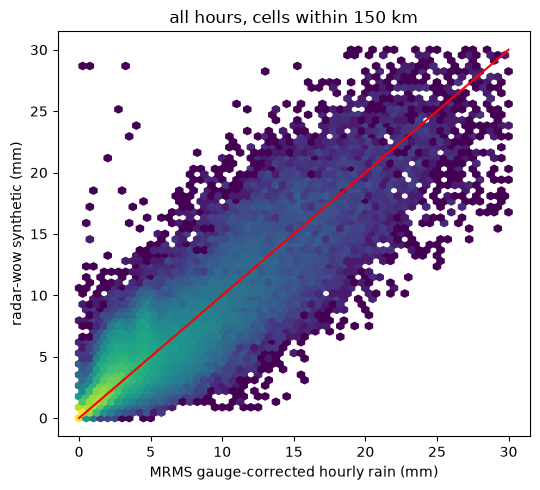

In [8]:
ref_all, ours_all = [], []
for h in HOURS:
    o, t_, d_ = to_mrms_grid(maps[(h, "synthetic")], lat, lon, maps[(h, "mrms")], gk)
    ours_all.append(o)
    ref_all.append(t_)
o, t_ = np.concatenate(ours_all), np.concatenate(ref_all)
m = np.isfinite(o) & np.isfinite(t_) & ((o > 0.1) | (t_ > 0.1))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.hexbin(t_[m], o[m], gridsize=60, bins="log", extent=(0, 30, 0, 30))
ax.plot([0, 30], [0, 30], "r")
ax.set(xlabel="MRMS gauge-corrected hourly rain (mm)", ylabel="radar-wow synthetic (mm)", title="all hours, cells within 150 km")
fig.tight_layout()
fig.savefig(f"{FIG}/03_scatter.png", dpi=110)
plt.show()

## Takeaways
- **First end-to-end result.** From raw KTLX files to hourly rain, with no gauge information, the radar-wow
  synthetic estimate is within +6 to +18 % of the gauge-corrected MRMS total in each hour and correlates at
  0.77-0.94. MRMS's own radar-only product overestimates more (+10 to +26 %) but correlates better (0.97-0.99),
  partly because the gauge-corrected product is that same field adjusted, and partly because MRMS combines
  several radars and corrects for storm motion between scans (our map shows streaks from moving cells).
- **Range matters.** Within 100 km the bias is small; at 100-150 km we overestimate by 17-53 %: the beam is
  1 deg wide and starts to sample the melting layer, whose bright band inflates Z. That is the case for the
  next stage, VPR correction (Zhang & Qi 2010). The ML mask itself changes little here because the 0.5 deg beam
  centre stays below the ML bottom (2.5 km) out to ~150 km; the contamination comes from the upper part of the beam.
- **The melting layer from QVPs agrees with the model 0 C level** when there is rain over the radar; a
  temporal tracker is needed to reject false detections from low non-meteorological echo.
- **Open:** in the last hour the synthetic estimate correlates worse than plain Marshall-Palmer; advection-
  corrected accumulation, VPR and a multi-radar mosaic are not yet in; one case, one radar, one season.